# Building Design and Energy Needs
**Phase 4 · Modeling and Evaluation | Team Game Theory**

Predict heating and cooling loads from eight design features. To rerun, put `ENB2012_data_cleaned.csv` beside this notebook and select **Run All**. [UCI dataset](https://archive.ics.uci.edu/dataset/242/energy+efficiency)

In [1]:
#imports
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, GroupKFold, GroupShuffleSplit
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVR


In [2]:
SEED = 42

## 1. Load the Phase 3 features and targets

In [3]:
data = pd.read_csv("ENB2012_data_cleaned.csv")

targets = ["Heating Load", "Cooling Load"]
X = data.drop(columns=targets)
y = data[targets]
shape_features = ["Relative Compactness", "Surface Area", "Wall Area (m^2)",
                  "Roof Area (m^2)", "Overall Height (m)"]
category_features = ["Orientation", "Glazing Area Distribution"]
numeric_features = shape_features + ["Glazing Area"]
groups = X.groupby(shape_features, sort=True).ngroup()

## 2. Split by building shape

Use nine shapes for training and validation. Reserve three unseen shapes (192 designs) for testing.

In [4]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=SEED)
train_idx, test_idx = next(splitter.split(X, groups=groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
train_groups, test_groups = groups.iloc[train_idx], groups.iloc[test_idx]
cv = GroupKFold(n_splits=3)

assert set(train_groups).isdisjoint(test_groups)
for fit_idx, val_idx in cv.split(X_train, groups=train_groups):
    assert set(train_groups.iloc[fit_idx]).isdisjoint(train_groups.iloc[val_idx])

print(f"Development set: {len(X_train)} designs in {train_groups.nunique()} geometries")
print(f"Final test set:  {len(X_test)} designs in {test_groups.nunique()} geometries")

Development set: 576 designs in 9 geometries
Final test set:  192 designs in 3 geometries


## 3. Tune four model families

Compare KNN, Ridge, support vector regression (SVR), and Random Forest. Select the lowest mean absolute error (MAE) across three validation folds using 79 settings per target.

In [5]:
models = {
    "KNN": (
        KNeighborsRegressor(),
        {"model__n_neighbors": [3, 5, 9, 15, 25], "model__weights": ["uniform", "distance"],
         "model__p": [1, 2]},
    ),
    "Ridge": (
        Ridge(),
        {"model__alpha": [0.01, 0.1, 1, 10, 100]},
    ),
    "RBF SVR": (
        SVR(kernel="rbf"),
        {"model__C": [1, 10, 100, 1000], "model__gamma": ["scale", 0.01, 0.1],
         "model__epsilon": [0.1, 0.5, 1.0]},
    ),
    "Random Forest": (
        RandomForestRegressor(n_estimators=120, random_state=SEED),
        {"model__max_depth": [4, 8, None], "model__min_samples_leaf": [1, 3, 6],
         "model__max_features": [0.75, 1.0]},
    ),
}

In [6]:
fitted = {}
tuning_rows = []

for target in targets:
    for family, (estimator, param_grid) in models.items():
        numeric_step = "passthrough" if family == "Random Forest" else StandardScaler()
        preprocess = ColumnTransformer([
            ("numeric", numeric_step, numeric_features),
            ("categories", OneHotEncoder(handle_unknown="ignore"), category_features),
        ])
        pipeline = Pipeline([("preprocess", preprocess), ("model", estimator)])
        search = GridSearchCV(pipeline, param_grid, cv=cv, scoring="neg_mean_absolute_error",
                              refit=True, error_score="raise")
        search.fit(X_train, y_train[target], groups=train_groups)
        fitted[target, family] = search.best_estimator_

        best_settings = ", ".join(f"{key.removeprefix('model__')}={value}"
                                  for key, value in search.best_params_.items())
        tuning_rows.append({
            "Target": target, "Family": family,
            "Settings tried": len(search.cv_results_["params"]),
            "CV MAE": -search.best_score_,
            "Fold SD": search.cv_results_["std_test_score"][search.best_index_],
            "Best settings": best_settings,
        })

tuning = pd.DataFrame(tuning_rows)
winner_rows = tuning.groupby("Target", sort=False)["CV MAE"].idxmin()
selected = tuning.loc[winner_rows].set_index("Target")["Family"]
print("Selected from training folds")
for target in targets:
    print(f"{target}: {selected[target]}")
with pd.option_context("display.max_colwidth", None, "display.max_columns", None):
    display(tuning.set_index(["Target", "Family"]).round(3))

Selected from training folds
Heating Load: RBF SVR
Cooling Load: RBF SVR


Settings tried  CV MAE  Fold SD  \
Target       Family                                           
Heating Load KNN                        20   3.772    1.861   
             Ridge                       5   3.648    0.782   
             RBF SVR                    36   3.306    1.515   
             Random Forest              18   4.962    2.690   
Cooling Load KNN                        20   3.735    1.522   
             Ridge                       5   3.776    1.072   
             RBF SVR                    36   3.026    1.468   
             Random Forest              18   4.566    2.439   

                                                                 Best settings  
Target       Family                                                             
Heating Load KNN                           n_neighbors=5, p=1, weights=uniform  
             Ridge                                                   alpha=100  
             RBF SVR                              C=1, epsilon=0.5, gamma=0.01  
             Random Forest  max_depth=4, max_features=0.75, min_samples_leaf=3  
Cooling Load KNN                          n_neighbors=25, p=1, weights=uniform  
             Ridge                                                   alpha=100  
             RBF SVR                              C=1, epsilon=1.0, gamma=0.01  
             Random Forest  max_depth=4, max_features=0.75, min_samples_leaf=3

## 4. Test results

Compare each tuned model with the training-mean baseline. Lower MAE and RMSE and higher R² indicate better predictions.

In [7]:
test_rows = []
predictions = {}

for target in targets:
    mean_model = DummyRegressor(strategy="mean").fit(X_train, y_train[target])
    test_models = {"Training mean": mean_model, **{family: fitted[target, family] for family in models}}
    for family, model in test_models.items():
        predicted = pd.Series(model.predict(X_test), index=X_test.index)
        predictions[target, family] = predicted
        actual = y_test[target]
        test_rows.append({
            "Target": target, "Family": family, "CV choice": "Yes" if family == selected[target] else "",
            "MAE": mean_absolute_error(actual, predicted),
            "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
            "R²": r2_score(actual, predicted),
        })

scores = pd.DataFrame(test_rows).set_index(["Target", "Family"])
display(scores.round(3))

CV choice    MAE   RMSE     R²
Target       Family                                      
Heating Load Training mean            8.268  8.878 -0.166
             KNN                      1.586  2.042  0.938
             Ridge                    2.464  2.754  0.888
             RBF SVR             Yes  3.235  3.367  0.832
             Random Forest            3.170  3.520  0.817
Cooling Load Training mean            8.555  9.093 -0.102
             KNN                      3.120  3.465  0.840
             Ridge                    3.527  4.133  0.772
             RBF SVR             Yes  3.890  4.394  0.743
             Random Forest            4.338  4.815  0.691

### Predicted versus simulated load

The dashed line marks a perfect prediction.

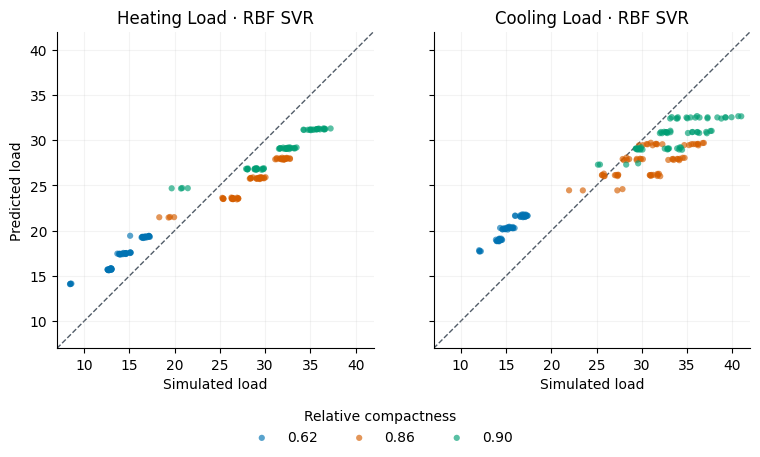

In [8]:
compactness = X_test["Relative Compactness"]
colors = ["#0072B2", "#D55E00", "#009E73"]
fig, axes = plt.subplots(1, 2, figsize=(9.2, 4.8), sharex=True, sharey=True)
chosen_values = [predictions[target, selected[target]].to_numpy() for target in targets]
all_values = np.concatenate([y_test.to_numpy().ravel(), *chosen_values])
limits = (np.floor(all_values.min()) - 1, np.ceil(all_values.max()) + 1)

for ax, target in zip(axes, targets):
    predicted = predictions[target, selected[target]]
    ax.plot(limits, limits, "--", color="#515C68", linewidth=1, zorder=1)
    for shape, color in zip(sorted(compactness.unique()), colors):
        rows = compactness == shape
        ax.scatter(y_test.loc[rows, target], predicted.loc[rows], label=f"{shape:.2f}",
                   s=20, alpha=0.65, color=color, edgecolors="none", zorder=2)
    ax.set(title=f"{target} · {selected[target]}", xlabel="Simulated load", xlim=limits, ylim=limits)
    ax.set_aspect("equal", adjustable="box")
    ax.grid(alpha=0.15)
    ax.spines[["top", "right"]].set_visible(False)

axes[0].set_ylabel("Predicted load")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title="Relative compactness", loc="lower center", ncol=3, frameon=False)
fig.subplots_adjust(bottom=0.22, wspace=0.12)
plt.show()

In [9]:
shape_errors = pd.DataFrame({"Relative compactness": compactness})
for target in targets:
    shape_errors[f"{target} MAE"] = (y_test[target] - predictions[target, selected[target]]).abs()
shape_summary = shape_errors.groupby("Relative compactness").mean()
shape_summary.insert(0, "Designs", shape_errors.groupby("Relative compactness").size())
display(shape_summary.round(3))

,Designs,Heating Load MAE,Cooling Load MAE
Relative compactness,,,
0.62,64,3.012,4.889
0.86,64,3.328,3.428
0.90,64,3.363,3.354


## 5. Feature importance

Shuffle geometry, glazing, or orientation separately. A larger increase in MAE means the model relied more on that group.

In [10]:
feature_groups = {
    "Geometry": shape_features,
    "Glazing": ["Glazing Area", "Glazing Area Distribution"],
    "Orientation": ["Orientation"],
}
rng = np.random.default_rng(SEED)
row_orders = [rng.permutation(len(X_test)) for _ in range(20)]
reliance = pd.DataFrame(index=list(feature_groups))

for target in targets:
    family = selected[target]
    model = fitted[target, family]
    original_mae = scores.loc[(target, family), "MAE"]
    for group_name, columns in feature_groups.items():
        shuffled_errors = []
        for order in row_orders:
            shuffled = X_test.copy()
            shuffled[columns] = X_test.iloc[order][columns].to_numpy()
            shuffled_errors.append(mean_absolute_error(y_test[target], model.predict(shuffled)))
        reliance.loc[group_name, target] = np.mean(shuffled_errors) - original_mae

reliance.index.name = "Shuffled features"
display(reliance.rename(columns={target: f"{target} · increase in MAE" for target in targets}).round(4))

,Heating Load · increase in MAE,Cooling Load · increase in MAE
Shuffled features,,
Geometry,4.2618,4.0918
Glazing,0.7014,0.4684
Orientation,-0.0002,0.0021


## Findings

- SVR had the lowest validation MAE for both loads.
- KNN had the lowest test MAE on the three unseen shapes, **1.60 for heating** and **3.13 for cooling**.
- Geometry had the largest effect on the selected SVR models’ prediction errors.